# Part 5 — Training with Fokker–Planck regularisation
Paper Eq. 10, Fig. 1 (bottom row), Fig. 6, Table 1. See [README.md](README.md).

⚠️ FP training is ~5–8× slower than plain DSM (extra forward/backward passes, App. C.3). Each model takes a few
minutes on a laptop CPU; results are cached in `results/`.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent            # notebooks live one level below the project root
sys.path.insert(0, str(ROOT))
import numpy as np, torch, matplotlib.pyplot as plt
torch.set_default_dtype(torch.float64)      # float64: the FP estimator uses finite differences with sigma=1e-4
torch.set_num_threads(8)
from scoremd import sde, models, losses, sampling, simulate, metrics, potentials, plotting, experiments as ex
%matplotlib inline

## 1. Figure 1 bottom row: Gaussian mixture with DSM + α·FP

loaded gmm_diffusion_seed0.pt
loaded gmm_fp_seed0.pt
DSM only : small-mode mass  iid 0.191 | p0 0.091 | exact 0.200
DSM + FP : small-mode mass  iid 0.233 | p0 0.194 | exact 0.200


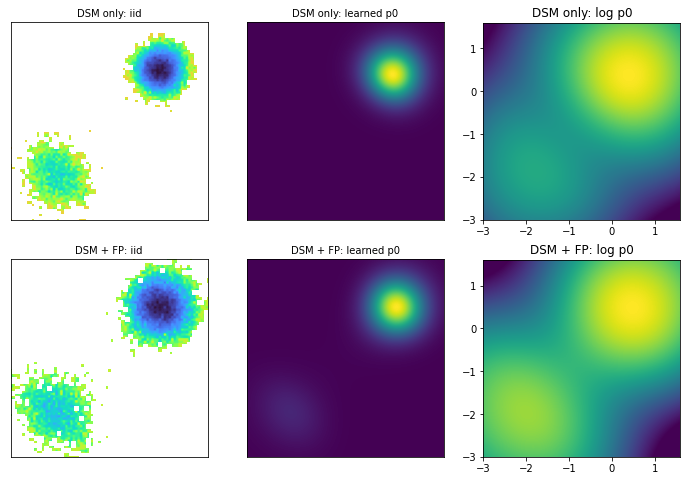

In [2]:
x, info = ex.load_system('gmm')
m_dsm = ex.get_model('gmm_diffusion')
m_fp = ex.get_model('gmm_fp')
R = [[-3.0, 1.6], [-3.0, 1.6]]   # normalised coords: small mode near (-1.94,-1.94), big mode near (0.49,0.49)
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for row, (name, m) in enumerate([('DSM only', m_dsm), ('DSM + FP', m_fp)]):
    s = ex.iid_samples(m, n=20_000, steps=500)
    Xg, Yg, lp = metrics.grid_log_density(m.log_p, R)
    p = np.exp(lp); small = p[(Xg + Yg) < 0].sum() / p.sum()
    plotting.free_energy_hist(ax[row, 0], s, R, bins=80, title=f'{name}: iid')
    plotting.density_image(ax[row, 1], Xg, Yg, lp, f'{name}: learned p0')
    ax[row, 2].imshow(lp, origin='lower', extent=[-3.0, 1.6, -3.0, 1.6], vmin=lp.max() - 15); ax[row, 2].set_title(f'{name}: log p0')
    print(f'{name:9s}: small-mode mass  iid {float((s.sum(1) < 0).double().mean()):.3f} | p0 {small:.3f} | exact 0.200')

## 2. FP error vs. t, with and without regularisation (Fig. 6)

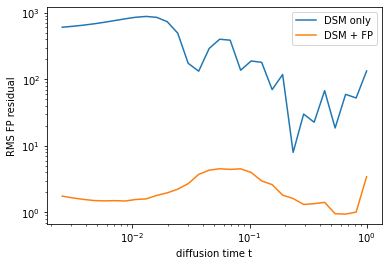

In [3]:
def fp_error_curve(model, x, ts, n=1000):
    out = []
    for tv in ts:
        tt = torch.full((n,), float(tv)); xt, _, _ = sde.perturb(x[:n], tt)
        out.append(float(losses.fp_residual_exact(model, xt, tt).pow(2).mean().sqrt()))
    return out
ts = torch.logspace(-2.6, 0, 30)   # t from ~0.0025 (FD needs t > h_s = 1e-3) to 1, log-spaced to resolve small t
plt.semilogy(ts, fp_error_curve(m_dsm, x, ts), label='DSM only')
plt.semilogy(ts, fp_error_curve(m_fp, x, ts), label='DSM + FP')
plt.xscale('log'); plt.xlabel('diffusion time t'); plt.ylabel('RMS FP residual'); plt.legend()

## 3. Müller–Brown: does simulation become consistent?

loaded mb_diffusion_seed0.pt
loaded mb_fp_seed0.pt
reference small-basin fraction: 0.13691
mb_diffusion {'iid': {'pmf': 3.514866734952879, 'js': 0.037013273158401534}, 'sim': {'pmf': 5.878286722636023, 'js': 0.13395215265329102}, 'basin_iid': 0.12365, 'basin_sim': 0.068}
mb_fp {'iid': {'pmf': 11.614645880992802, 'js': 0.22482829817956704}, 'sim': {'pmf': 11.89720850949185, 'js': 0.21783564772265265}, 'basin_iid': 0.3085, 'basin_sim': 0.15383333333333332}


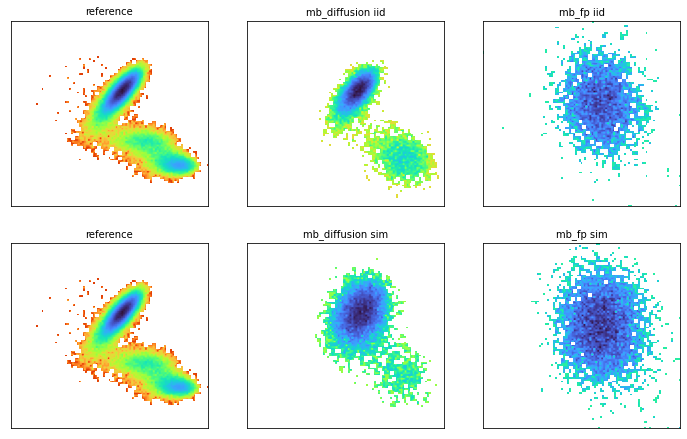

In [4]:
x, info = ex.load_system('mb'); rng = metrics.hist_range(x)
results = {}
fig, ax = plt.subplots(2, 3, figsize=(12, 7.5))
plotting.free_energy_hist(ax[0, 0], x, rng, title='reference'); plotting.free_energy_hist(ax[1, 0], x, rng, title='reference')
for col, name in enumerate(['mb_diffusion', 'mb_fp'], start=1):
    m = ex.get_model(name)
    iid = ex.iid_samples(m); sim, _ = ex.simulate_model(m, x)
    plotting.free_energy_hist(ax[0, col], iid, rng, title=f'{name} iid'); plotting.free_energy_hist(ax[1, col], sim, rng, title=f'{name} sim')
    results[name] = dict(iid=ex.compare(iid, x), sim=ex.compare(sim, x),
                         basin_iid=ex.mb_small_basin_fraction(iid, info), basin_sim=ex.mb_small_basin_fraction(sim, info))
print('reference small-basin fraction:', ex.mb_small_basin_fraction(x, info))
for k, v in results.items(): print(k, v)

## 4. α sweep: the consistency / sample-quality trade-off (optional, slow)
Each α trains a new model (~4 min). Set `RUN_SWEEP = True` to run. The paper notes larger α improves sim but can
slightly degrade iid (Table 1).

In [5]:
RUN_SWEEP = False
if RUN_SWEEP:
    rows = []
    for alpha in [0.0, 0.03, 0.1, 0.3, 1.0]:
        m = ex.get_model('mb_fp', alpha=alpha) if alpha > 0 else ex.get_model('mb_diffusion')
        iid = ex.iid_samples(m); sim, _ = ex.simulate_model(m, x)
        rows.append((alpha, ex.compare(iid, x)['pmf'], ex.compare(sim, x)['pmf'], ex.mb_small_basin_fraction(sim, info)))
        print(rows[-1])
    a = np.array(rows)
    plt.semilogx(a[1:, 0], a[1:, 1], 'o-', label='iid PMF'); plt.semilogx(a[1:, 0], a[1:, 2], 's-', label='sim PMF'); plt.legend(); plt.xlabel('alpha')

## Exercises
* Use the paper's literal weighting `λ_FP = λ = s(t)²`: `ex.get_model('mb_fp', ...)` doesn't expose it, so call
  `scoremd.train.train(model, x, fp_alpha=..., fp_kwargs={'weight': lambda t: sde.marginal_std(t)**2})` directly.
  What happens to the FP error at small `t`?
* Try `fp_kwargs={'unbiased': False}` (squared single residual). Is training noisier or more biased?